# Textual Restoration Tool: final project code

One pipeline for a degraded manuscript page:

1. **Detect** the degradation: **stain**, **blur** or **bleed-through** (or **clean** if none is found).
2. **Restore** the page with the method built for that degradation.

| Degradation | Detection | Restoration | Author |
|---|---|---|---|
| Stain | Paper background that is darker **and** redder (browner) than the page, as large blobs (`is_stain`) | Tri-Level Semi-Adaptive Thresholding (Rani et al. 2022), adapted with a stain mask for iron-gall ink (`restore_zoernikav`) | Sam |
| Bleed-through | Detector C: intermediate-tone components away from dark ink, weighted by weaker edges (`bleedthrough_features`) | Background normalisation, then Otsu, then edge gate (`binarize`) | Joeal |
| Blur | Laplacian-variance reduction after a further σ=1 Gaussian blur (`detect_blur_percentage`) | Unsharp masking (`sharpen_unsharp`) | Mohit |

**Routing order: stain, then blur, then bleed-through.** The bleed-through detector is the least specific of the three. It also fires on stained and blurred pages, which Joeal's notebook reports as known confounders. It is therefore checked last, only once stain and blur have been ruled out. Section 5 explains the order and the thresholds.

**Usage:** set `INPUT_PATH` in the next cell and run all cells. Results are written to `OUT_DIR`. Requires only `opencv-python`, `numpy` and `matplotlib`. The scikit-image functions Joeal used (Otsu, multi-Otsu, speck removal) are re-implemented in section 1 with OpenCV/NumPy.

## 0. Setup

In [3]:
import os, glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---- change this to the image you want to restore ----
# INPUT_PATH = 'Sam/StainImages/Zoernikav folio212.jpg'
INPUT_PATH = 'Sam/StainImages/H05.png'

OUT_DIR = 'final_output'

os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams['figure.dpi'] = 110


def load_image(path):
    # Load any image as 8-bit BGR (greyscale scans are replicated to 3 channels).
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f'Image not found: {path}')
    return img


def to_gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def show(images, titles=None, cols=2, width=16):
    # Show images in a grid; greyscale uses a fixed 0-255 scale.
    n = len(images)
    rows = (n + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(width, width / cols * h / w * rows + 0.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis('off')
        if i < n:
            img = images[i]
            if img.ndim == 2:
                ax.imshow(img, cmap='gray', vmin=0, vmax=255)
            else:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            if titles:
                ax.set_title(titles[i], fontsize=10)
    plt.tight_layout(); plt.show()

## 1. Shared helpers

Replacements for the three scikit-image functions used in Joeal's code, so the notebook only needs OpenCV and NumPy:

- `otsu_threshold`: global Otsu (OpenCV).
- `multiotsu_3`: three-class Otsu by exhaustive search over the 256-bin histogram. It returns thresholds `(low, high)` with the same class convention as `skimage.filters.threshold_multiotsu`: `<= low`, `(low, high]`, `> high`.
- `remove_specks`: removes 4-connected components of `max_size` pixels or fewer, like `skimage.morphology.remove_small_objects`.

The bleed-through scores reproduce the ones saved in Joeal's `real_detection_scores.csv` (e.g. H02 4.490, H05 1.171, H03 0.202).

In [2]:
def otsu_threshold(gray):
    t, _ = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return float(t)


def multiotsu_3(gray):
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    levels = np.arange(256)
    w, m = np.cumsum(p), np.cumsum(p * levels)
    i, j = levels[:, None], levels[None, :]
    w0, m0 = w[i], m[i]
    w1, m1 = w[j] - w[i], m[j] - m[i]
    w2, m2 = 1 - w[j], m[-1] - m[j]
    with np.errstate(divide='ignore', invalid='ignore'):
        between = m0 ** 2 / w0 + m1 ** 2 / w1 + m2 ** 2 / w2   # maximise between-class variance
    between[~np.isfinite(between)] = -1
    between[np.tril_indices(256)] = -1                          # require low < high
    low, high = np.unravel_index(np.argmax(between), between.shape)
    return int(low), int(high)


def remove_specks(mask, max_size):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=4)
    keep = stats[:, cv2.CC_STAT_AREA] > max_size
    keep[0] = False
    return keep[lab]

## 2. Stain (Sam)

### 2.1 Detection: `is_stain`

A stain is a large patch of paper that is **darker and redder (browner)** than the typical page. Shadows and dark edges are darker but not redder, so they are ignored.

1. Shrink to ~300 px for speed.
2. Estimate the paper: dilation erases ink and bleed-through, and a median blur smooths the result.
3. In LAB space, mark pixels with L below the page median by more than `dark` (8%) **and** `a*` (red-green) above the median by more than `min_red`.
4. Keep only blobs of at least 0.5% of the page. The stained fraction is their total area.

In [6]:
def is_stain(image, dark=0.08, min_red=1.8, min_area=0.01):
    # Returns (is_stained, stained_fraction_of_page).
    if image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)
    s = min(1.0, 300 / max(image.shape[:2]))
    small = cv2.resize(image, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    w = small.shape[1]

    # Paper background: dilate erases ink / bleed-through, median blur smooths
    k = max(3, int(w * 0.006) | 1)
    window = max(3, int(w * 0.04) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    bg = cv2.medianBlur(cv2.dilate(small, kernel), window)

    # Darker and redder than the typical paper
    lab = cv2.cvtColor(bg, cv2.COLOR_BGR2LAB).astype(np.float32)
    L, a = lab[:, :, 0], lab[:, :, 1]
    mask = (L < np.median(L) * (1 - dark)) & (a - np.median(a) > min_red)
    mask = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

    # Keep only large blobs
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    areas = stats[1:, cv2.CC_STAT_AREA]
    stain_fraction = areas[areas >= 0.005 * mask.size].sum() / mask.size
    return stain_fraction > min_area, float(stain_fraction)

### 2.2 Restoration: Tri-Level Semi-Adaptive Thresholding (TSAT)

> N. Shobha Rani, B. J. Bipin Nair, M. Chandrajith, G. Hemantha Kumar & J. Fortuny, "Restoration of deteriorated text sections in ancient document images using a tri-level semi-adaptive thresholding technique", *Automatika* 63(2), 2022, 378–398. DOI: 10.1080/00051144.2022.2042462.

Paper pipeline (§3.1–3.6):

- **Pre-enhancement:** per-channel contrast stretch (1–99%).
- **Gradient image G_d:** Otsu on `G − (R+B)/2` blanks the clean paper.
- **Level 1:** threshold T1 = mean of the distinct grey levels of G_d. Uneven illumination and foxing go to white.
- **Level 2:** threshold T2 = median distinct grey level. Impulse noise and moderate stains go to white.
- **Level 3:** threshold T3 = mean of one partition of the distinct levels. Stain marks crossing strokes go to white.
- **Pseudo-colouring:** applied inside the degradation mask B_d.
- **Post-enhancement:** bridging and dilation.

**Adaptation for Zoernikav's brown iron-gall ink (Sam):**

1. A morphological closing removes the ink, and Otsu on the remaining background gives a **stain mask**.
2. Level 3 is applied **only inside the stain**, and Level 2 everywhere else.
3. As well as the binary output, a **tone output** keeps the ink's grey levels for reading.

The `tone` image is the main output, for reading. `binary` is for OCR/HTR.

`close_size` must be wider than the thickest pen stroke. Sam's guide is about 31 px for a ~1200 px wide scan and about 81 px for a 3000 px one, so here it scales with width (minimum 15).

In [7]:
def remove_shadow(gray: np.ndarray, window: int | None = None, k: int | None = None) -> np.ndarray:
    """Erase ink with dilation, estimate the paper, divide it out."""
    if window is None:
        window = max(3, int(gray.shape[1] * 0.04) | 1)   # ~4% of width, always odd
    if k is None:
        k = max(3, int(gray.shape[1] * 0.006) | 1)        # wider than strokes, always odd

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    dilated = cv2.dilate(gray, kernel)
    background = cv2.medianBlur(dilated, window)
    background = np.maximum(background, 1)

    norm = cv2.divide(gray, background, scale=255)
    return np.clip(norm, 0, 255).astype(np.uint8)


def process_image(image: np.ndarray, window: int | None = None, k: int | None = None) -> np.ndarray:
    """Grayscale -> shadow/stain removal -> CLAHE -> sharpening."""
    if image is None or image.size == 0:
        raise ValueError("The input image is empty.")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    norm = remove_shadow(gray, window=window, k=k)

    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(16, 16))
    enhanced = clahe.apply(norm)

    blur = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=1.0)
    sharp = cv2.addWeighted(enhanced, 1.6, blur, -0.6, 0)

    return cv2.cvtColor(sharp, cv2.COLOR_GRAY2BGR)

def remove_stain(image):
    out = process_image(image)
    gray = cv2.cvtColor(out, cv2.COLOR_BGR2GRAY)
    return dict(output=out, binary=gray, method='remove_shadow + CLAHE + unsharp')

## 3. Bleed-through (Joeal)

### 3.1 Detection: `bleedthrough_features` (detector C)

Bleed-through is ink seen **through** the paper, so it is lighter and softer than front-side ink.

1. Downscale to ≤1200 px and divide out a broad Gaussian illumination estimate. This copy is used for analysis only.
2. Three-class Otsu splits the page into dark (front ink), middle (candidate ghost ink) and bright (paper).
3. Middle-class components **away from** the dark ink, of plausible text size and shape, are candidates.
4. Each candidate is weighted by how much **weaker its edges** are than the front ink's edges.
5. Score = weighted candidate area / front-ink area. The page counts only if the evidence is credible: at least 3 components and at least 0.1% of the page.

The score is **not** a probability. Joeal's exploratory cutoff was 0.04 (see section 5).

In [8]:
def luminance(image):
    """Convert an OpenCV-order colour array to 8-bit grayscale."""
    if image.ndim == 2:
        return image
    blue, green, red = np.moveaxis(image.astype(np.int32), -1, 0)
    return ((3735 * blue + 19235 * green + 9798 * red + 16384) >> 15).astype(np.uint8)


def _groups(image):
    counts = np.bincount(image.ravel(), minlength=256)
    levels = np.flatnonzero(counts)
    counts = counts[levels]
    weight = np.r_[0, np.cumsum(counts, dtype=np.float64)]
    moment = np.r_[0, np.cumsum(counts * levels, dtype=np.float64)]
    return levels, weight, moment


def threshold_otsu(image):
    """Pick the split that maximises the weighted separation of two groups."""
    levels, weight, moment = _groups(image)
    if len(levels) == 1:
        return int(levels[0])

    left = weight[1:-1]
    right = weight[-1] - left
    left_mean = moment[1:-1] / left
    right_mean = (moment[-1] - moment[1:-1]) / right
    separation = left * right * (left_mean - right_mean) ** 2
    return int(levels[np.argmax(separation)])


def remove_specks(mask, max_size):
    """Keep 4-connected foreground components larger than max_size."""
    _, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=4
    )
    keep = stats[:, cv2.CC_STAT_AREA] > max_size
    keep[0] = False
    return keep[labels]


PARAMS = dict(
    close_size=31,       # step 1: closing kernel, larger than any stroke width
    median_size=21,      # step 1: smooths the background estimate
    min_speck=30,        # step 2: components of this many pixels or fewer are removed
    canny=(60, 150),     # step 3: Canny thresholds on the original image
    min_edge_ratio=0.08, # step 3: edge pixels / component size needed to count as real ink
)


def bg_normalise(gray, close_size, median_size):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    background = cv2.medianBlur(cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se), median_size)
    norm = np.clip(gray.astype(float) / np.maximum(background, 1) * 255, 0, 255).astype(np.uint8)
    return norm, background


def edge_gate(binary, gray, canny, min_edge_ratio):
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3, 3), 0), *canny) > 0
    nl, lab = cv2.connectedComponents(binary.astype(np.uint8), connectivity=8)
    edge_cnt = np.bincount(lab[edges], minlength=nl)
    size = np.bincount(lab.ravel(), minlength=nl)
    keep = edge_cnt / np.maximum(size, 1) > min_edge_ratio
    keep[0] = False                                   # label 0 is background
    return keep[lab], edges


def binarize(gray, p=PARAMS):
    norm, background = bg_normalise(gray, p['close_size'], p['median_size'])          # step 1
    t = threshold_otsu(norm)
    thresh = remove_specks(norm < t, p['min_speck'])                  # step 2
    final, edges = edge_gate(thresh, gray, p['canny'], p['min_edge_ratio'])           # step 3
    return final, dict(background=background, normalised=norm, otsu_t=t,
                       thresholded=thresh, edges=edges, removed_by_gate=thresh & ~final)

### 3.2 Restoration: background normalisation, then Otsu, then edge gate

1. **Background normalisation:** a 31 px closing erases the strokes, and a 21 px median smooths the result. Dividing the page by this background estimate flattens stains, yellowing and lighting.
2. **Otsu + speck removal:** once the page is flattened, front ink is the darkest thing on it. Blobs of 30 px or fewer are removed.
3. **Edge gate:** Canny edges are computed on the original. A blob is kept only if more than 8% of its pixels are edges. Ghost ink seen through the paper is soft, and real ink is sharp.

On the nine DIBCO pages this scored mean F 90.7, pF 94.7 and DRD 2.57, and never went below F 85.1 (Joeal's `DIBCO_bleedthrough_eval.ipynb`). The output is binary, with ink black and background white.

In [ ]:
def luminance(image):
    """Convert an OpenCV-order colour array to 8-bit grayscale."""
    if image.ndim == 2:
        return image
    blue, green, red = np.moveaxis(image.astype(np.int32), -1, 0)
    return ((3735 * blue + 19235 * green + 9798 * red + 16384) >> 15).astype(np.uint8)


def _groups(image):
    counts = np.bincount(image.ravel(), minlength=256)
    levels = np.flatnonzero(counts)
    counts = counts[levels]
    weight = np.r_[0, np.cumsum(counts, dtype=np.float64)]
    moment = np.r_[0, np.cumsum(counts * levels, dtype=np.float64)]
    return levels, weight, moment


def threshold_otsu(image):
    """Pick the split that maximises the weighted separation of two groups."""
    levels, weight, moment = _groups(image)
    if len(levels) == 1:
        return int(levels[0])

    left = weight[1:-1]
    right = weight[-1] - left
    left_mean = moment[1:-1] / left
    right_mean = (moment[-1] - moment[1:-1]) / right
    separation = left * right * (left_mean - right_mean) ** 2
    return int(levels[np.argmax(separation)])


def remove_specks(mask, max_size):
    """Keep 4-connected foreground components larger than max_size."""
    _, labels, stats, _ = cv2.connectedComponentsWithStats(
        mask.astype(np.uint8), connectivity=4
    )
    keep = stats[:, cv2.CC_STAT_AREA] > max_size
    keep[0] = False
    return keep[labels]


PARAMS = dict(
    close_size=31,       # step 1: closing kernel, larger than any stroke width
    median_size=21,      # step 1: smooths the background estimate
    min_speck=30,        # step 2: components of this many pixels or fewer are removed
    canny=(60, 150),     # step 3: Canny thresholds on the original image
    min_edge_ratio=0.08, # step 3: edge pixels / component size needed to count as real ink
)


def bg_normalise(gray, close_size, median_size):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    background = cv2.medianBlur(cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se), median_size)
    norm = np.clip(gray.astype(float) / np.maximum(background, 1) * 255, 0, 255).astype(np.uint8)
    return norm, background


def edge_gate(binary, gray, canny, min_edge_ratio):
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3, 3), 0), *canny) > 0
    nl, lab = cv2.connectedComponents(binary.astype(np.uint8), connectivity=8)
    edge_cnt = np.bincount(lab[edges], minlength=nl)
    size = np.bincount(lab.ravel(), minlength=nl)
    keep = edge_cnt / np.maximum(size, 1) > min_edge_ratio
    keep[0] = False                                   # label 0 is background
    return keep[lab], edges


def binarize(gray, p=PARAMS):
    norm, background = bg_normalise(gray, p['close_size'], p['median_size'])          # step 1
    t = threshold_otsu(norm)
    thresh = remove_specks(norm < t, p['min_speck'])                  # step 2
    final, edges = edge_gate(thresh, gray, p['canny'], p['min_edge_ratio'])           # step 3
    return final, dict(background=background, normalised=norm, otsu_t=t,
                       thresholded=thresh, edges=edges, removed_by_gate=thresh & ~final)

def remove_bleedthrough(image):
    gray = luminance(image) if image.ndim == 3 else image
    mask, steps = binarize(gray)
    ink_on_white = np.where(mask, 0, 255).astype(np.uint8)
    return dict(
        output=ink_on_white,
        binary=(mask.astype(np.uint8) * 255),
        method='bg normalisation + Otsu + edge gate',
        steps=steps,
    )

## 4. Blur (Mohit)

### 4.1 Detection: `detect_blur_percentage`

The variance of the Laplacian measures how much fine detail an image has. A sharp page loses most of that variance when it is blurred **a little more** (σ = 1). A page that is already blurred has little left to lose.

- reduction = (var_before − var_after) / var_before × 100
- **reduction < 45% means blurred.** This is the cutoff in Mohit's `process_image`.

This relative measure is used instead of the raw Laplacian variance (`detect_blur`, threshold 100 or 40), because the raw value depends on resolution and on how much text is on the page. For example, the 4000 px photographs score below 40 even when sharp. Both values are reported.

### 4.2 Restoration: unsharp masking

`sharpened = (1 + strength)·image − strength·GaussianBlur(image, σ)`, with strength 1.5 and σ 1.0. Mohit compared this against Laplacian sharpening and CLAHE + unsharp. Non-blind Wiener deconvolution (`Defocus_Blur.ipynb`, `Motion_Blur.ipynb`) needs the true blur kernel, which is unknown for a real scan, so it is not used here.

In [7]:
def detect_blur(gray, threshold=100):
    score = cv2.Laplacian(gray, cv2.CV_64F).var()
    return score < threshold, float(score)


def detect_blur_percentage(gray, sigma=1):
    original_score = cv2.Laplacian(gray, cv2.CV_64F).var()
    blurred_score = cv2.Laplacian(cv2.GaussianBlur(gray, (0, 0), sigmaX=sigma), cv2.CV_64F).var()
    reduction = (original_score - blurred_score) / max(original_score, 1e-10) * 100
    return float(reduction), float(original_score), float(blurred_score)


def sharpen_unsharp(image, strength=1.5, sigma=1.0):
    smooth = cv2.GaussianBlur(image, (0, 0), sigma)
    return cv2.addWeighted(image, 1 + strength, smooth, -strength, 0)


def remove_blur(image):
    return dict(output=sharpen_unsharp(to_gray(image)), method='Unsharp masking (strength 1.5, sigma 1.0)')

## 5. Classifier: which degradation is it?

All three detectors run on every image. Their evidence is reported, and the **first** one that fires, in this order, decides the label:

1. **Stain.** Its evidence is colour plus a large area, measured on a heavily smoothed background. Blur does not affect it, and grey bleed-through on paper does not trigger it.
2. **Blur.** Its evidence is relative loss of detail, which does not depend on stains or ghost ink.
3. **Bleed-through.** Its evidence is mid-tone, soft-edged components. Stains and blur produce exactly the same evidence, so it is only trusted once both have been ruled out.
4. Otherwise the page is **clean** and returned unchanged.

**Thresholds.** These were measured on the team's sample images: the 6 stained Zoernikav folios, the unstained Zoernikav page, 9 DIBCO bleed-through pages, 3 clean controls and Mohit's `test2.png`, each also blurred with σ = 2 and σ = 4.

| Detector | Original cutoff | Used here | Why |
|---|---|---|---|
| Stain fraction | 0.01 (Sam) | **0.05** | Real stains score 0.15–0.23. With 0.01, bleed-through page H07 (0.019) and blurred `test2` (0.019) were wrongly routed to stain removal. |
| Blur reduction | 45% (Mohit) | **45%** | Sharp pages score 50–95%, σ = 2 blur scores 20–41% and σ = 4 scores 2–9%. The cutoff separates them cleanly. |
| Bleed-through score | 0.04 (Joeal) | **0.10** | DIBCO bleed-through pages score 0.16–4.5. Clean pages score 0.05–0.07: unstained Zoernikav 0.053, skimage page 0.051, `test2` 0.072. Joeal's 0.04 would flag every page. |

These thresholds were chosen on the same small set they are evaluated on, so they are engineering choices, not validated accuracy. Joeal's notebook also records a false positive on a blurred, unevenly lit phone photograph (`15_92`, score 0.25). Change them in `THRESHOLDS`.

In [4]:
THRESHOLDS = dict(
    stain_min_fraction=0.05,      # Sam's is_stain(min_area); his default was 0.01
    blur_max_reduction=45.0,      # Mohit's process_image cutoff
    bleed_min_score=0.10,         # Joeal's detector C cutoff; his exploratory value was 0.04
)


def classify_degradation(image, thresholds=THRESHOLDS):
    # Run all three detectors and return the label plus every piece of evidence.
    gray = to_gray(image)

    stained, stain_fraction = is_stain(image, min_area=thresholds['stain_min_fraction'])
    reduction, lap_var, _ = detect_blur_percentage(gray)
    blurred = reduction < thresholds['blur_max_reduction']
    bt = bleedthrough_features(image, edge_threshold=thresholds['bleed_min_score'])

    if stained:
        label = 'stain'
    elif blurred:
        label = 'blur'
    elif bt['detected']:
        label = 'bleed-through'
    else:
        label = 'clean'

    return dict(
        label=label,
        stain=dict(detected=stained, fraction=stain_fraction),
        blur=dict(detected=blurred, reduction_pct=reduction, laplacian_var=lap_var),
        bleed=dict(detected=bt['detected'], score=bt['score'], credible=bt['credible'],
                   components=bt['num_components']),
    )


def print_report(name, c):
    s, b, t = c['stain'], c['blur'], c['bleed']
    print(f"{name}\n  -> detected: {c['label'].upper()}")
    print(f"     stain         {'YES' if s['detected'] else 'no ':3}  stained fraction = {s['fraction']:.3f}"
          f"  (>= {THRESHOLDS['stain_min_fraction']})")
    print(f"     blur          {'YES' if b['detected'] else 'no ':3}  Laplacian reduction = {b['reduction_pct']:.1f}%"
          f"  (< {THRESHOLDS['blur_max_reduction']}%)   raw Laplacian var = {b['laplacian_var']:.1f}")
    print(f"     bleed-through {'YES' if t['detected'] else 'no ':3}  score = {t['score']:.3f}"
          f"  (>= {THRESHOLDS['bleed_min_score']}, credible={t['credible']}, {t['components']} components)")

## 6. Detect, then restore

`restore_document()` classifies the page and applies **only** the matching method. A clean page is returned unchanged.

In [10]:
RESTORERS = {
    'stain': remove_stain,           # Sam
    'blur': remove_blur,             # Mohit
    'bleed-through': remove_bleedthrough,  # Joeal
}


def restore_document(image, thresholds=THRESHOLDS):
    c = classify_degradation(image, thresholds)
    if c['label'] == 'clean':
        result = dict(output=image.copy(), method='none (no degradation detected)')
    else:
        result = RESTORERS[c['label']](image)
    result['classification'] = c
    return result


def save_result(path, result, out_dir=OUT_DIR):
    stem = os.path.splitext(os.path.basename(path))[0]
    label = result['classification']['label'].replace('-', '')
    out_path = os.path.join(out_dir, f'{stem}_{label}_restored.png')
    cv2.imwrite(out_path, result['output'])
    if 'binary' in result:   # stain route also has an OCR-ready binary
        cv2.imwrite(os.path.join(out_dir, f'{stem}_{label}_binary.png'), result['binary'])
    return out_path

NameError: name 'remove_blur' is not defined

## 7. Run on `INPUT_PATH`

Sam/StainImages/Zoernikav folio212.jpg
  -> detected: STAIN
     stain         YES  stained fraction = 0.231  (>= 0.05)
     blur          no   Laplacian reduction = 75.0%  (< 45.0%)   raw Laplacian var = 305.4
     bleed-through YES  score = 0.113  (>= 0.1, credible=True, 505 components)
  -> method applied: remove_shadow + CLAHE + unsharp
  -> saved: final_output\Zoernikav folio212_stain_restored.png


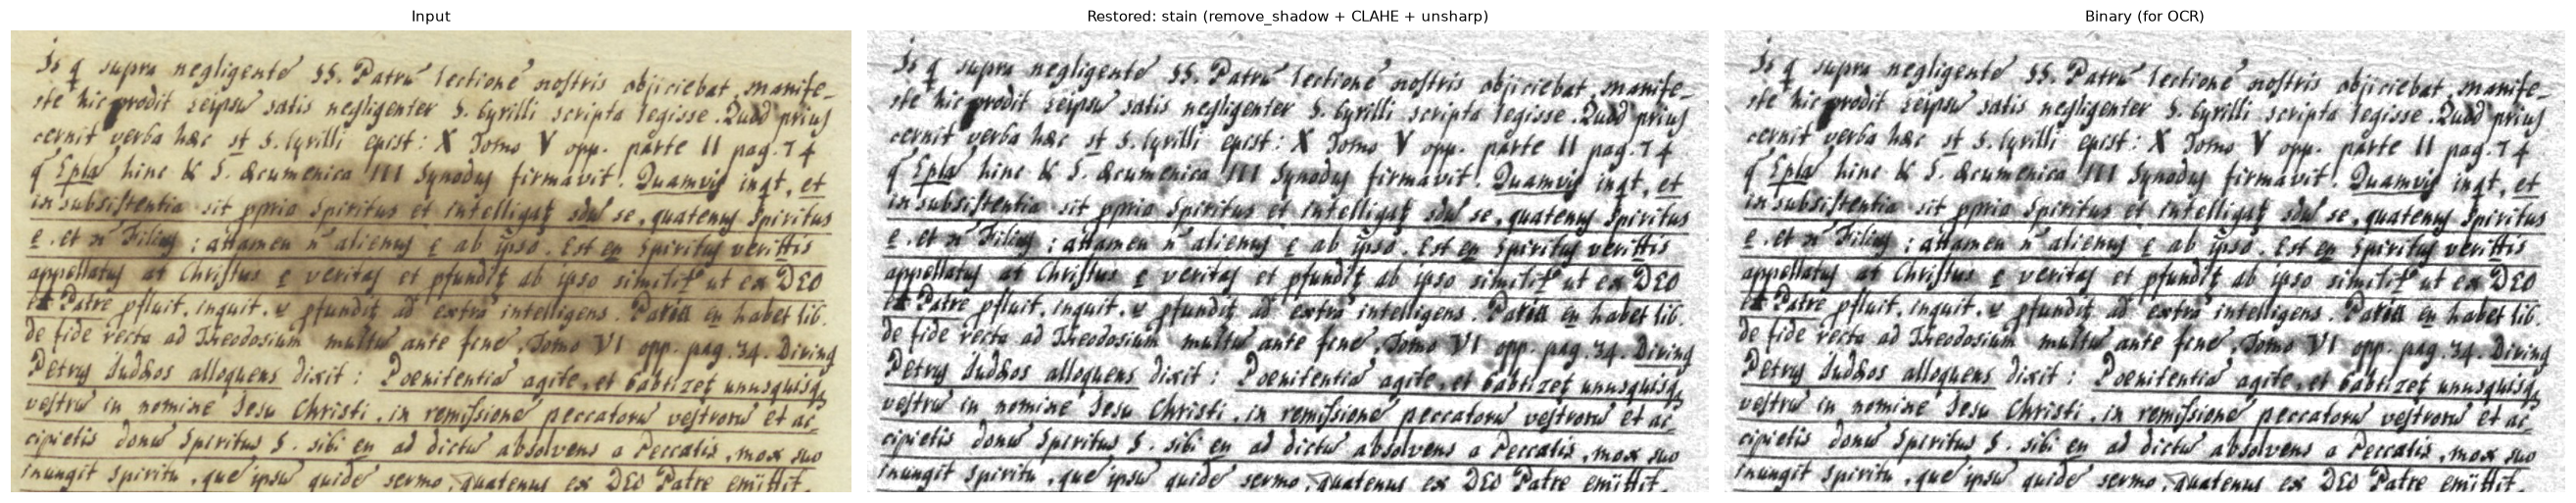

In [ ]:
image = load_image(INPUT_PATH)
result = restore_document(image)

print_report(INPUT_PATH, result['classification'])
print(f"  -> method applied: {result['method']}")
print(f"  -> saved: {save_result(INPUT_PATH, result)}")

label = result['classification']['label']
panels, titles = [image, result['output']], ['Input', f'Restored: {label} ({result["method"]})']
if 'binary' in result:
    panels.append(result['binary']); titles.append('Restored')
show(panels, titles, cols=len(panels), width=8 * len(panels))

## 8. Demonstration: one image per route

Sample images that are already in the repository:

- `Sam/StainImages/Zoernikav folio212.jpg`: a stained folio, which should route to **stain**.
- `Sam/StainImages/H05.png`: H-DIBCO 2010 bleed-through, which should route to **bleed-through**.
- `Sam/StainImages/notstainedimageZoernikav.jpeg`: an unstained page, which should be **clean**.
- The same unstained page blurred with a Gaussian of σ = 3, which should route to **blur**. This copy is made in code.

Stained folio (folio212)
  -> detected: STAIN
     stain         YES  stained fraction = 0.231  (>= 0.05)
     blur          no   Laplacian reduction = 75.0%  (< 45.0%)   raw Laplacian var = 305.4
     bleed-through YES  score = 0.113  (>= 0.1, credible=True, 505 components)
  -> method applied: TSAT + stain mask (close_size=27)



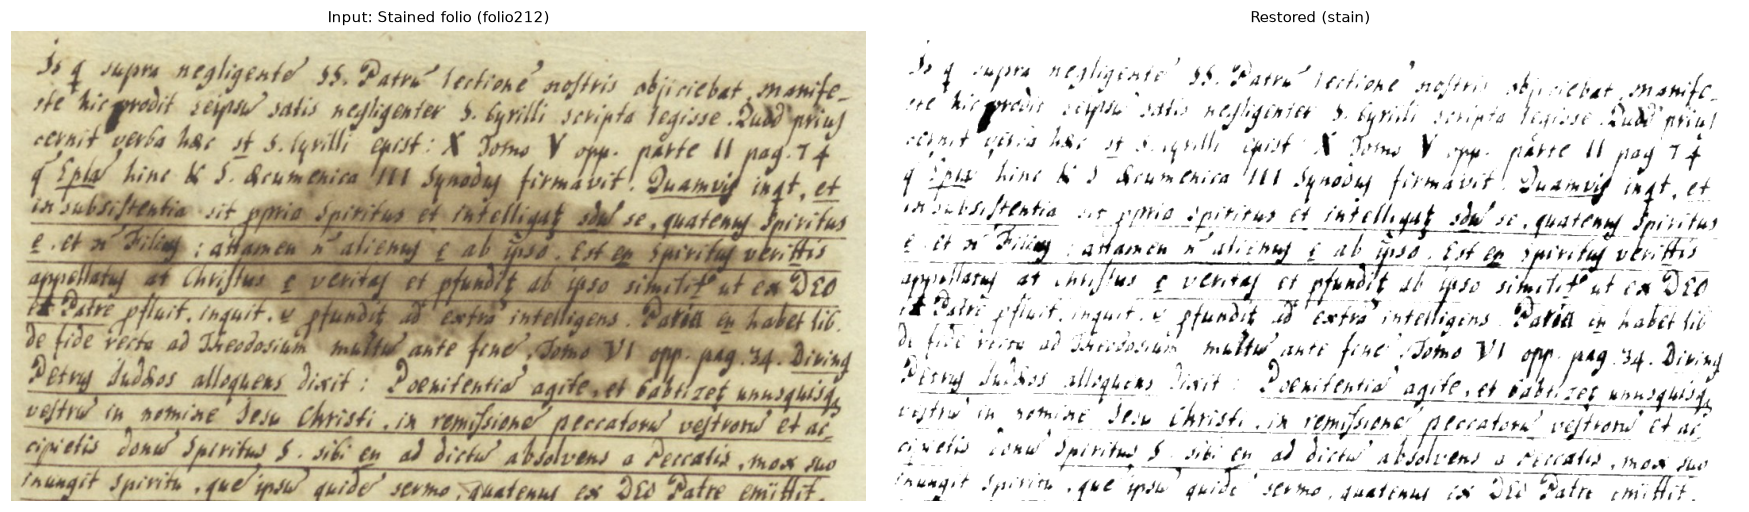

Bleed-through (H-DIBCO 2010 H05)
  -> detected: BLEED-THROUGH
     stain         no   stained fraction = 0.000  (>= 0.05)
     blur          no   Laplacian reduction = 81.1%  (< 45.0%)   raw Laplacian var = 334.8
     bleed-through YES  score = 1.171  (>= 0.1, credible=True, 202 components)
  -> method applied: BgNorm + Otsu + edge gate



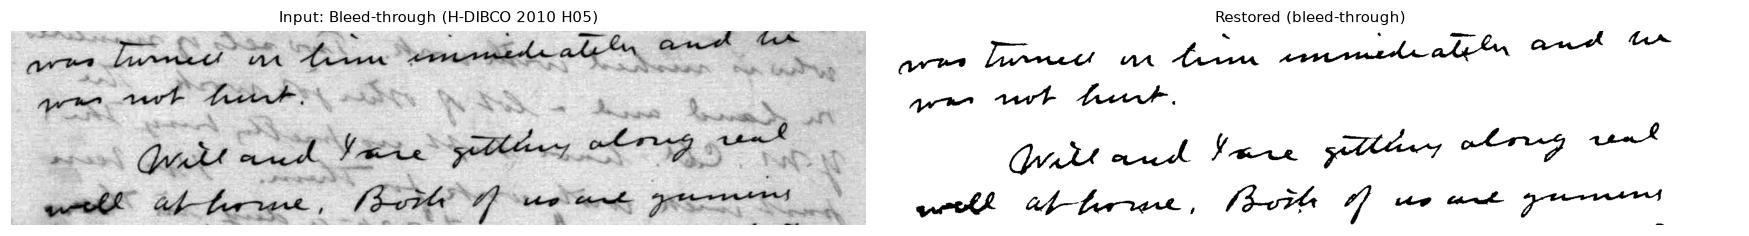

Unstained page
  -> detected: CLEAN
     stain         no   stained fraction = 0.000  (>= 0.05)
     blur          no   Laplacian reduction = 66.4%  (< 45.0%)   raw Laplacian var = 87.2
     bleed-through no   score = 0.053  (>= 0.1, credible=True, 252 components)
  -> method applied: none (no degradation detected)



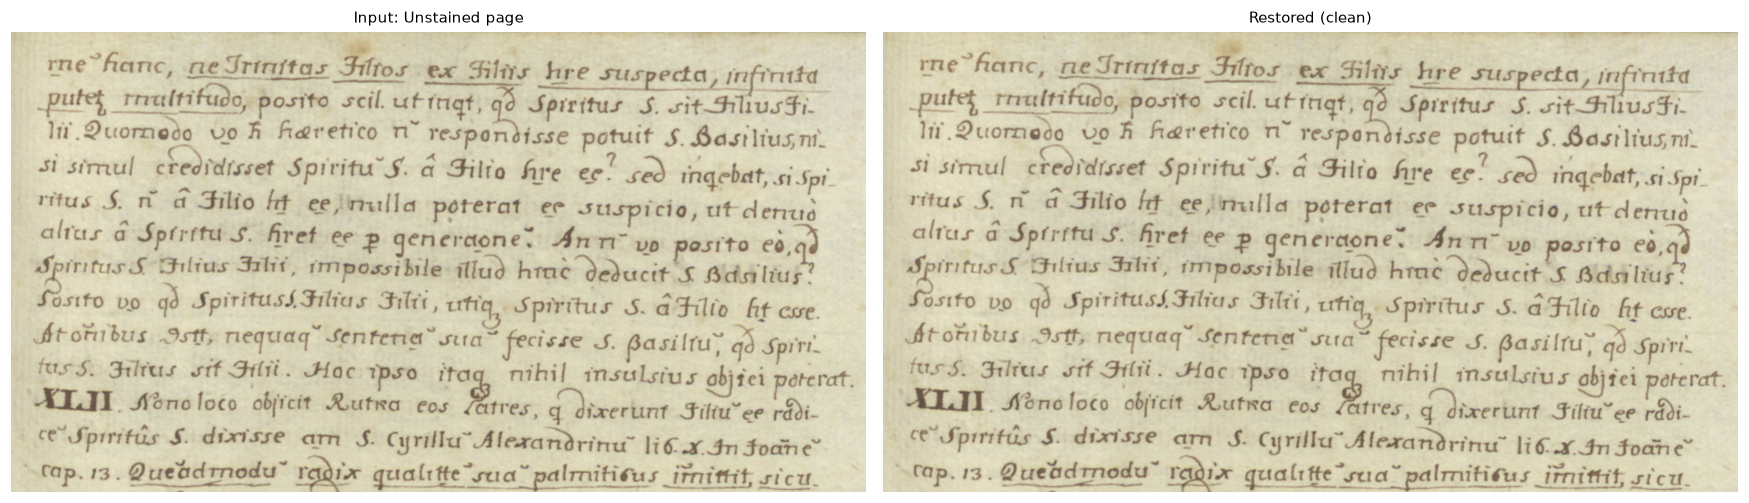

Unstained page, Gaussian blur sigma=3
  -> detected: BLUR
     stain         no   stained fraction = 0.000  (>= 0.05)
     blur          YES  Laplacian reduction = 13.4%  (< 45.0%)   raw Laplacian var = 3.5
     bleed-through YES  score = 0.225  (>= 0.1, credible=True, 1264 components)
  -> method applied: Unsharp masking (strength 1.5, sigma 1.0)



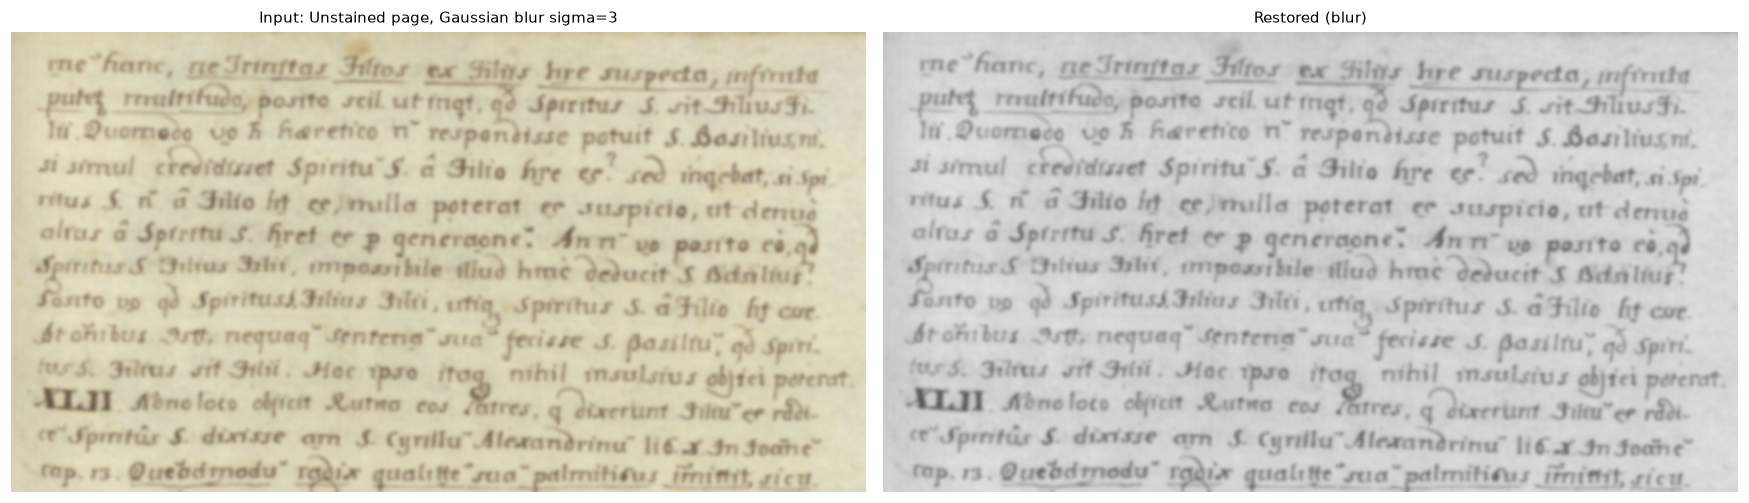

In [11]:
demo = {
    'Stained folio (folio212)': load_image('Sam/StainImages/Zoernikav folio212.jpg'),
    'Bleed-through (H-DIBCO 2010 H05)': load_image('Sam/StainImages/H05.png'),
    'Unstained page': load_image('Sam/StainImages/notstainedimageZoernikav.jpeg'),
}
demo['Unstained page, Gaussian blur sigma=3'] = cv2.GaussianBlur(demo['Unstained page'], (0, 0), 3)

for name, img in demo.items():
    r = restore_document(img)
    print_report(name, r['classification'])
    print(f"  -> method applied: {r['method']}\n")
    show([img, r['output']], ['Input: ' + name, f"Restored ({r['classification']['label']})"], cols=2, width=16)

### Batch: every image in a folder

Set `BATCH_DIR` to classify and restore every image in a folder. A summary table is printed, and every output is saved to `OUT_DIR`.

In [ ]:
BATCH_DIR = 'Sam/StainImages'

paths = sorted(p for ext in ('*.jpg', '*.jpeg', '*.png', '*.tif', '*.tiff')
               for p in glob.glob(os.path.join(BATCH_DIR, ext))
               if not any(tag in p for tag in ('_processed', '_stainmask', '_stainoverlay')))
print(f"{'image':38s} {'label':14s} {'stain':>7s} {'blur %':>7s} {'bleed':>7s}")
for p in paths:
    r = restore_document(load_image(p))
    c = r['classification']
    save_result(p, r)
    print(f"{os.path.basename(p)[:38]:38s} {c['label']:14s} {c['stain']['fraction']:7.3f} "
          f"{c['blur']['reduction_pct']:7.1f} {c['bleed']['score']:7.3f}")
print(f'\nSaved to {OUT_DIR}/')